<a href="https://colab.research.google.com/github/jessiek37185/CSCI046-Final-Project/blob/main/CSCI145_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This project was built using ideas and tools I learned throughout the course. I used ChatGPT along the way to help me think through coding structure, fix bugs, and better understand certain concepts while I was implementing them. All decisions about the design of the system, the experiments I ran, and the interpretation of the results were my own. The overall approach (neural network and multi-armed bandit algorithms) comes directly from topics we discussed in class and as suggested by the Professor. I also relied on documentation for PyTorch, NumPy, pandas, and matplotlib, as well as publicly available information from the Soridata K-Pop datasets, to support the technical parts of the project.

# Library Setup

In [ ]:
import matplotlib as mpl
mpl.rcParams['font.family'] = 'DejaVu Sans'
mpl.rcParams['axes.unicode_minus'] = False

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Loading Dataset

In [ ]:
!pip install -q gdown

import gdown

file_1 = "https://drive.google.com/uc?id=1qyVLw0C-WqB5OEW8etM5uLaYC_OV0SfC"
file_2 = "https://drive.google.com/uc?id=1MLX7aiX7yJzabXVwkHkV6AvtZofRAksR"

gdown.download(file_1, output="korean_artists.csv", quiet=False)
gdown.download(file_2, output="korean_videos.csv", quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1qyVLw0C-WqB5OEW8etM5uLaYC_OV0SfC
To: /content/korean_artists.csv
100%|██████████| 818k/818k [00:00<00:00, 123MB/s]
Downloading...
From: https://drive.google.com/uc?id=1MLX7aiX7yJzabXVwkHkV6AvtZofRAksR
To: /content/korean_videos.csv
100%|██████████| 3.59M/3.59M [00:00<00:00, 36.2MB/s]


'korean_videos.csv'

# Load the Artist and Video Data

In [ ]:
import pandas as pd

artists = pd.read_csv("korean_artists.csv")
videos = pd.read_csv("korean_videos.csv")

# Print Index Names

In [ ]:
print(artists.columns)
print(videos.columns)

Index(['Korean Artists: id', ' name', ' hangul', ' solo/group',
       ' date of birth (if solo)', ' member gender (or soloist gender)',
       ' full name (if solo)', ' debut video ID', ' debut date',
       ' disband date', ' fanclub name', ' sales (circle)', ' views',
       ' circle streaming score',
       ' circle streaming number of times charted (weekly)',
       ' circle streaming first places (weekly)',
       ' billboard global number of times charted', ' music show awards',
       ' yearly awards', ' paks'],
      dtype='object')
Index(['Music Videos: id', ' id_artist', ' name', ' original name', ' type',
       ' published date', ' pak (y/n)', ' views', ' likes',
       ' circle streaming score'],
      dtype='object')


# Clean and Standardize Column Names

In [ ]:
artists_clean = artists.copy()
artists_clean.columns = (
    artists_clean.columns
    .str.strip()
    .str.lower()
    .str.replace('[^a-z0-9_]', '_', regex=True)
)

videos_clean = videos.copy()
videos_clean.columns = (
    videos_clean.columns
    .str.strip()
    .str.lower()
    .str.replace('[^a-z0-9_]', '_', regex=True)
)

# Prepare Dataset for Neural Network Training + Multi-Armed Bandit Simulation

In [ ]:
# 1. Merge videos and artists
merged = videos_clean.merge(
    artists_clean,
    left_on="id_artist",
    right_on="korean_artists__id",
    how="left"
)

merged = merged.sample(1000, random_state=42).reset_index(drop=True)
merged["arm_id"] = merged.index


print("Using reduced dataset:")
print("Number of videos:", len(merged))

# 2. Extract numeric cols
numeric_cols = merged.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [
    c for c in numeric_cols
    if ("id" not in c) and (c != "award_binary")
]

video_df = merged[numeric_cols].fillna(0)

# 3. Normalize
video_df = (video_df - video_df.mean()) / (video_df.std() + 1e-6)

# 4. Convert to tensor
video_tensor = torch.tensor(video_df.values, dtype=torch.float32)

n_arms = video_tensor.shape[0]
input_dim = video_tensor.shape[1]

print("Feature dimension:", input_dim)

Using reduced dataset:
Number of videos: 1000
Feature dimension: 12


# Create Award Target
Creates the label that the neural network will learn to predict

In [ ]:
# CREATE AWARD TARGET (Binary)

if "music_show_awards" in merged.columns:
    merged["award_binary"] = (merged["music_show_awards"] > 0).astype(int)
elif "awards" in merged.columns:
    merged["award_binary"] = (merged["awards"] > 0).astype(int)
else:
    raise ValueError("No award column found in dataset.")

# Build target tensor
award_target = torch.tensor(merged["award_binary"].values, dtype=torch.float32)
X = video_tensor  # video features used for prediction

In [ ]:
print(merged.columns.tolist())

['music_videos__id', 'id_artist', 'name_x', 'original_name', 'type', 'published_date', 'pak__y_n_', 'views_x', 'likes', 'circle_streaming_score_x', 'korean_artists__id', 'name_y', 'hangul', 'solo_group', 'date_of_birth__if_solo_', 'member_gender__or_soloist_gender_', 'full_name__if_solo_', 'debut_video_id', 'debut_date', 'disband_date', 'fanclub_name', 'sales__circle_', 'views_y', 'circle_streaming_score_y', 'circle_streaming_number_of_times_charted__weekly_', 'circle_streaming_first_places__weekly_', 'billboard_global_number_of_times_charted', 'music_show_awards', 'yearly_awards', 'paks', 'arm_id', 'award_binary']


# (Neural Network) Fan Preference Model
Defines a neural network that learns to predict whether a Kpop MV is likely to win an award based on its features

In [ ]:
class AwardPredictor(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.out = nn.Linear(32, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return torch.sigmoid(self.out(x))  # predicted award probability

# Create 20 fans based on the trained AwardPredictor
def create_fan_from_trained(model, noise_scale=0.05):
    fan = AwardPredictor(input_dim)
    fan.load_state_dict(model.state_dict())

    # Add small noise to weights so each fan has slightly different preferences
    with torch.no_grad():
        for param in fan.parameters():
            param += noise_scale * torch.randn_like(param)
    return fan

model = AwardPredictor(input_dim)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.BCELoss()


# Train AwardPredictor
train the model to predict whehter a mv is likely to receive an award

In [ ]:
# train the single-user model
epochs = 200
for epoch in range(epochs):
    pred = model(X).squeeze()
    loss = loss_fn(pred, award_target)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch % 20 == 0:
        print(f"Epoch {epoch} | Loss = {loss.item():.4f}")

Epoch 0 | Loss = 0.6762
Epoch 20 | Loss = 0.5899
Epoch 40 | Loss = 0.5187
Epoch 60 | Loss = 0.4454
Epoch 80 | Loss = 0.3832
Epoch 100 | Loss = 0.3412
Epoch 120 | Loss = 0.3054
Epoch 140 | Loss = 0.2733
Epoch 160 | Loss = 0.2461
Epoch 180 | Loss = 0.2202


# Create 20 Different Fan Models
Each represents a unique user with slightly different preferences, but based on the same trained award-prediction model

In [ ]:
num_fans = 20
fans = [create_fan_from_trained(model) for _ in range(num_fans)]

# Reward Function
Determines whether a fan clicks(1) or doesn't (0) on a recommended mv

In [ ]:
def get_reward(fan_model, video_x):
    p = fan_model(video_x.unsqueeze(0)).item()
    return np.random.binomial(1, p)

# BANDIT ALGORITHMS:

# Epsilon-Greedy Bandit Algorithm
This explores a random video occasionally but otherwise recommends the video with the highest estimated reward, updating its estimates after each user interaction. This should balance exploration (trying new videos) and exploitation (showing the best-known video).

In [ ]:
# Epsilon-Greedy
class EpsilonGreedy:
    def __init__(self, n_arms, epsilon=0.1):
        self.n = n_arms # num of videos
        self.epsilon = epsilon # exploration rate 10%
        self.counts = np.zeros(n_arms) # tracks how many times each video has been recommended
        self.values = np.zeros(n_arms) # stores the estimated reward for each video

    def select_arm(self):
        if np.random.rand() < self.epsilon: # exploration vs. exploitation
            return np.random.randint(self.n)
        return np.argmax(self.values)

    def update(self, arm, reward):
        self.counts[arm] += 1
        n = self.counts[arm]
        value = self.values[arm]
        self.values[arm] = value + (reward - value) / n

# Upper Confidence Bound Algorithm
This is a more mathematical algorithm. It either chooses videos that are either known to perform well or haven't been explored enough.

In [ ]:
# UCB
class UCB:
    def __init__(self, n_arms):
        self.n = n_arms
        self.counts = np.zeros(n_arms)
        self.values = np.zeros(n_arms)
        self.total = 0

    def select_arm(self):
        self.total += 1
        if 0 in self.counts: # ensure every video is tried at least once
            return np.argmin(self.counts)

        ucb = self.values + np.sqrt(2 * np.log(self.total) / self.counts) # exploitation + exploration (uncertainty) bonus
        return np.argmax(ucb)

    def update(self, arm, reward):
        self.counts[arm] += 1
        self.values[arm] += (reward - self.values[arm]) / self.counts[arm]

# Thompson Sampling (Bayesian Bandit Algorithm)
This is a Bayesian approach to the problem. It treats every video's reward as an evolving probability distribution. At every round, it samples from these distributions and pikcs the video most likely to be the best.


In [ ]:
# Thompson Sampling
class ThompsonSampling:
    def __init__(self, n_arms):
        self.alpha = np.ones(n_arms) # num of successes
        self.beta = np.ones(n_arms) # num of failures

    def select_arm(self):
        return np.argmax(np.random.beta(self.alpha, self.beta))

    def update(self, arm, reward):
        if reward == 1:
            self.alpha[arm] += 1
        else:
            self.beta[arm] += 1

# Run the Simulation

In [ ]:
def run_simulation(bandit, T=5000, user_id=0):
    rewards = []
    arms = []

    fan = fans[user_id]  # fixed user for entire run

    for t in range(T):
        arm = bandit.select_arm()
        reward = get_reward(fan, video_tensor[arm])
        bandit.update(arm, reward)

        rewards.append(reward)
        arms.append(arm)

    return np.array(rewards), np.array(arms)

def run_all_algorithms_for_user(user_id, T=5000):
    bandits = {
        "ε-Greedy": EpsilonGreedy(n_arms),
        "UCB": UCB(n_arms),
        "Thompson": ThompsonSampling(n_arms)
    }

    rewards = {}
    arms = {}

    for name, bandit in bandits.items():
        r, a = run_simulation(bandit, T, user_id)
        rewards[name] = r
        arms[name] = a

    return rewards, arms

print("Running user-personalized bandit...")

Running user-personalized bandit...


# Loop
how each bandit algorithm performs across every fan (20)

Running Fan 0...


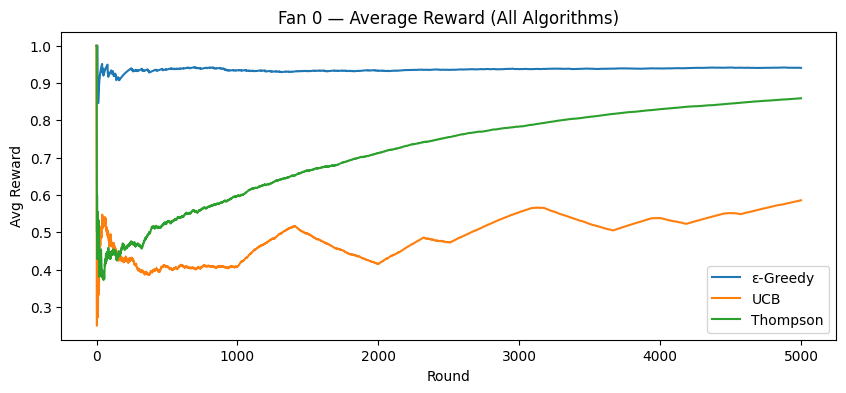

Running Fan 1...


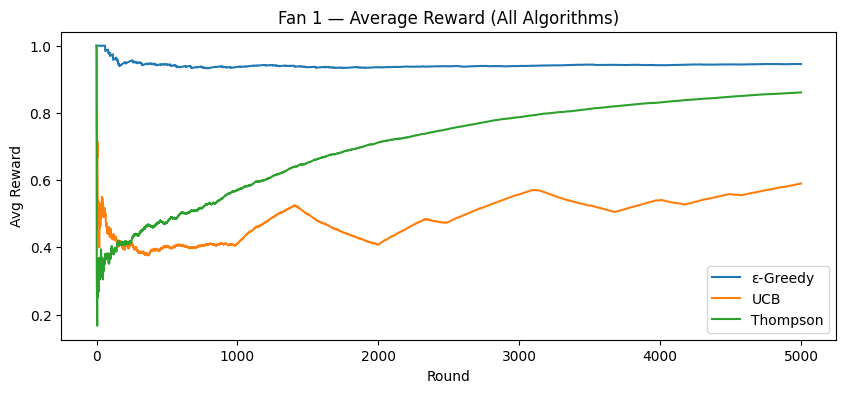

Running Fan 2...


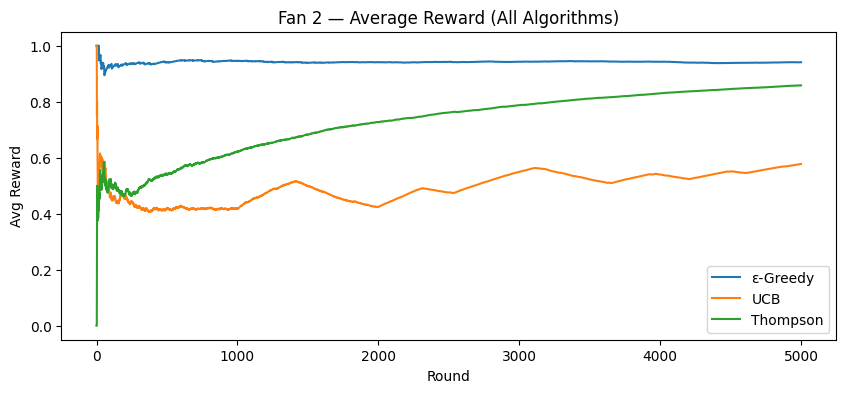

Running Fan 3...


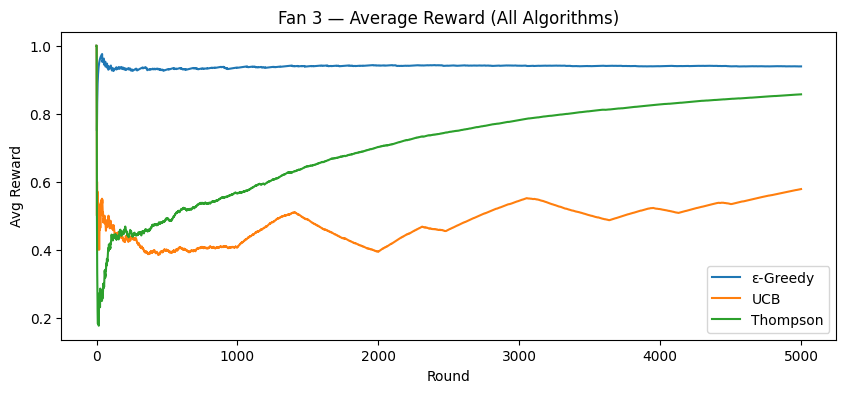

Running Fan 4...


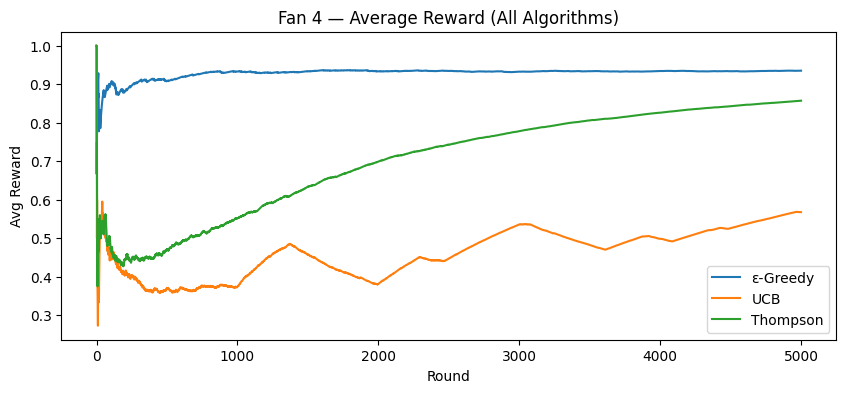

Running Fan 5...


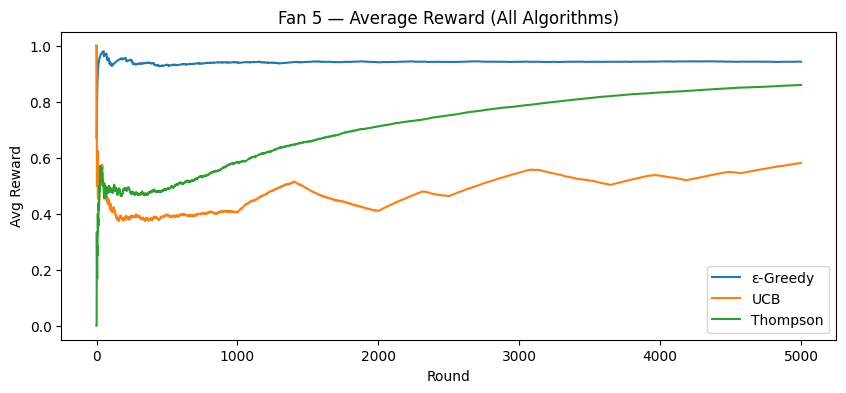

Running Fan 6...


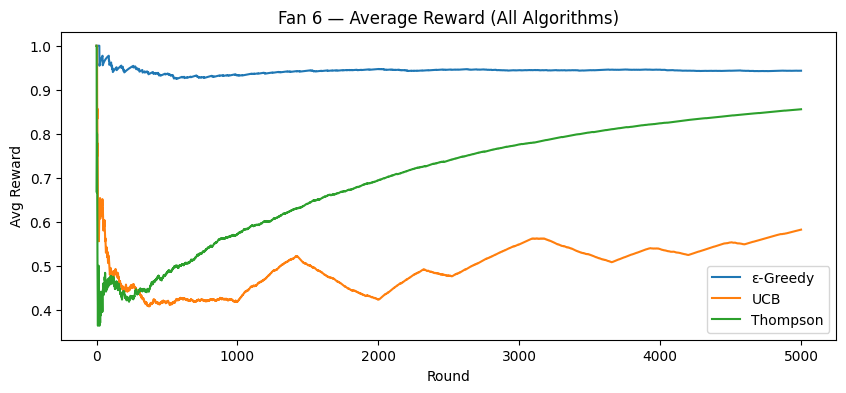

Running Fan 7...


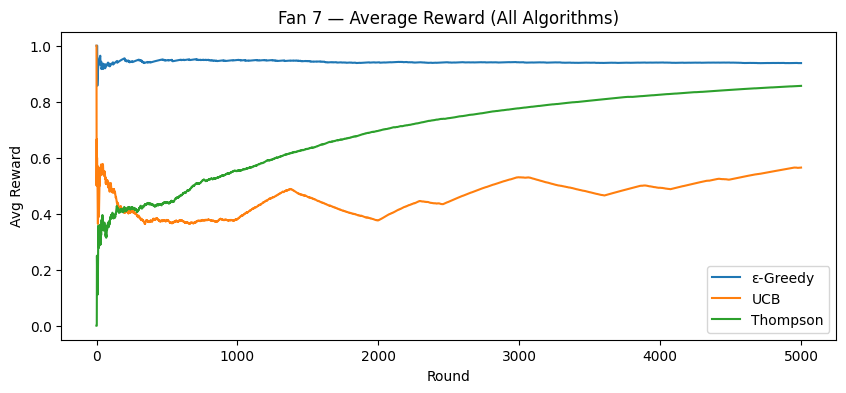

Running Fan 8...


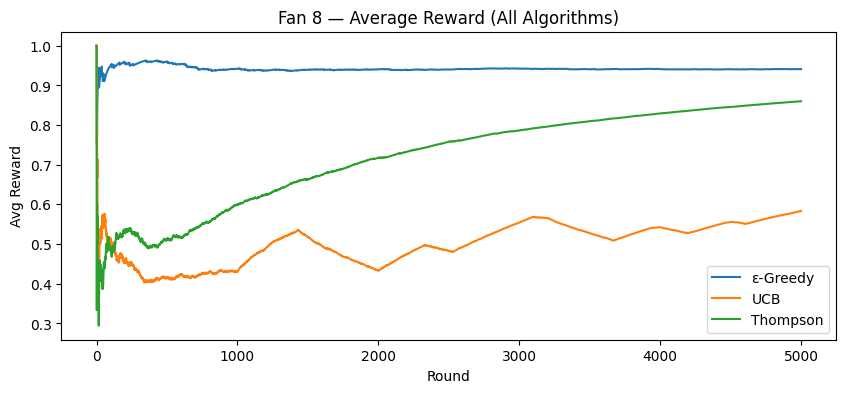

Running Fan 9...


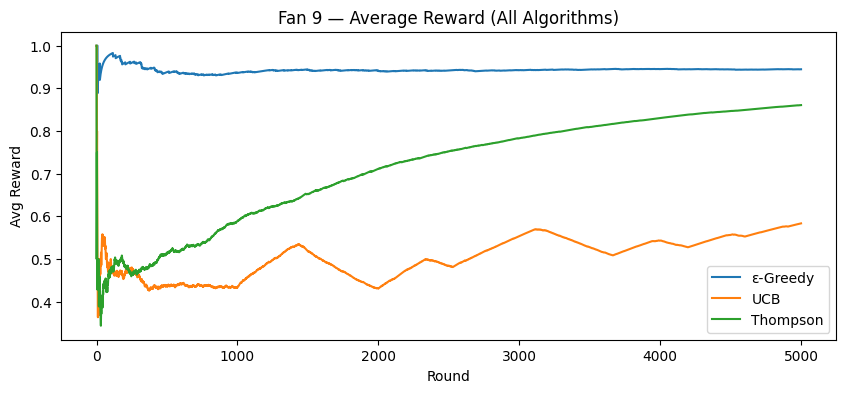

Running Fan 10...


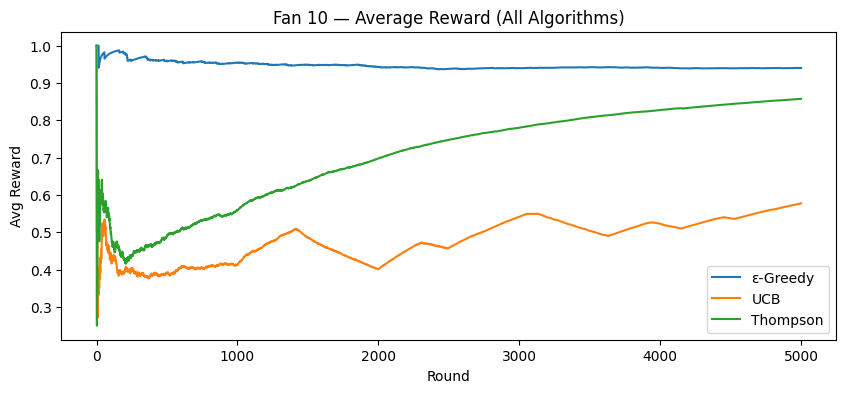

Running Fan 11...


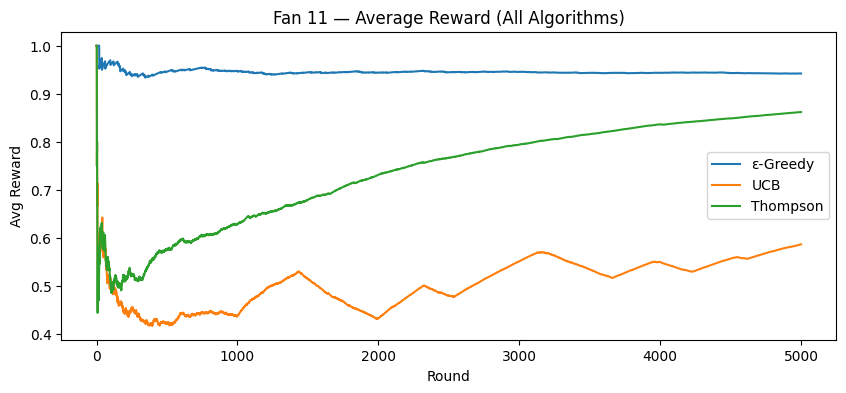

Running Fan 12...


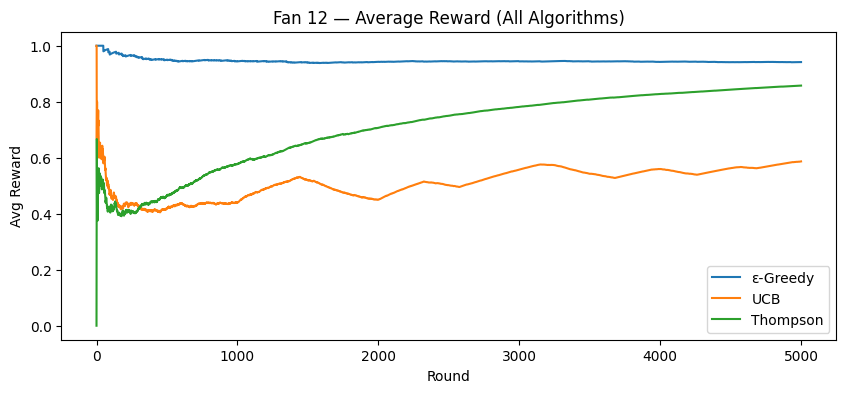

Running Fan 13...


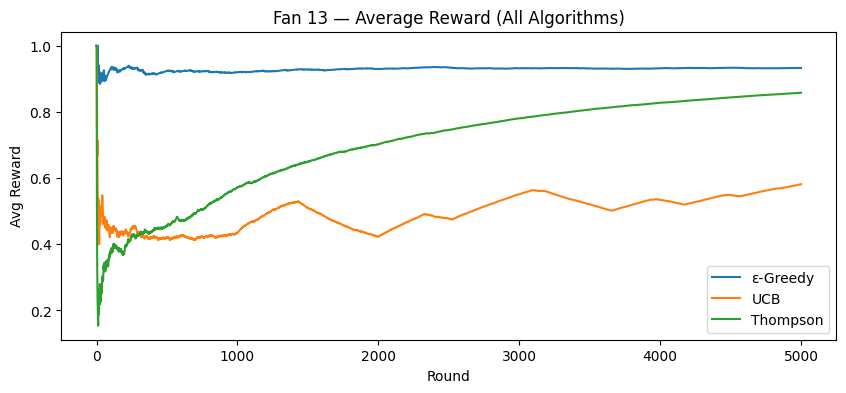

Running Fan 14...


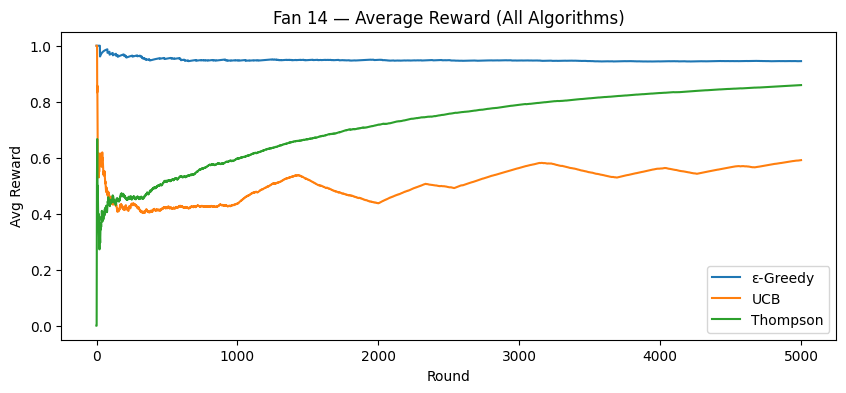

Running Fan 15...


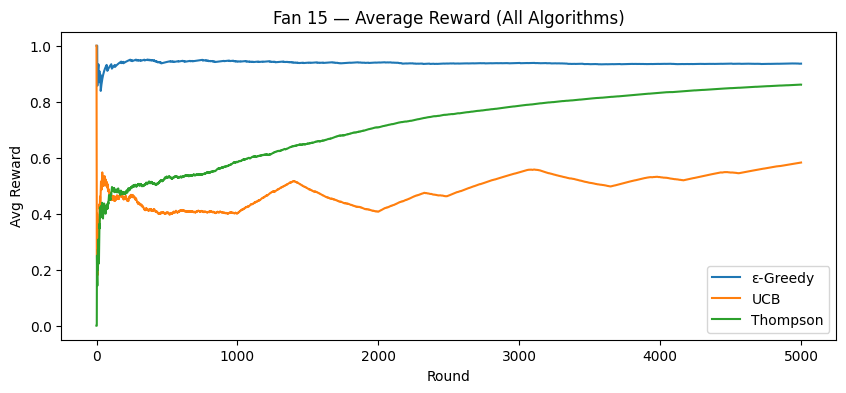

Running Fan 16...


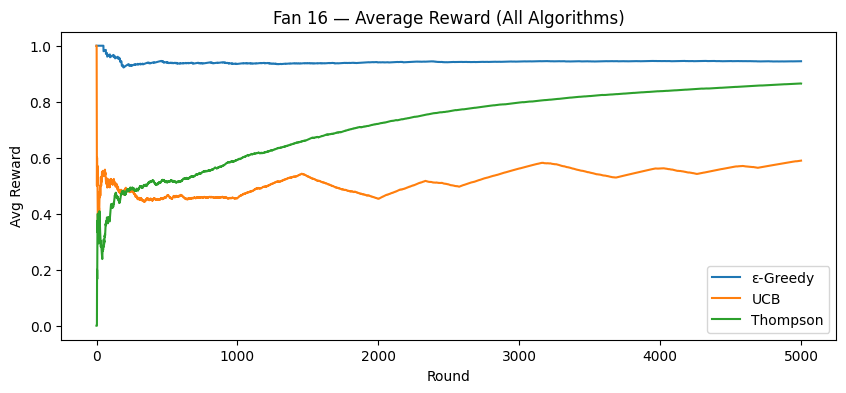

Running Fan 17...


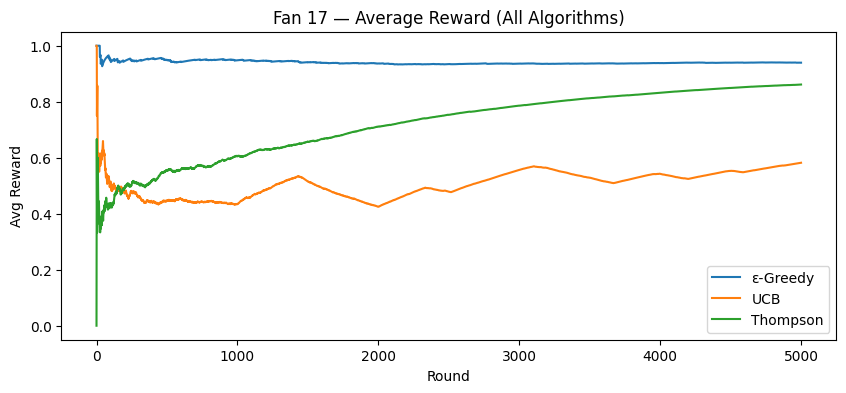

Running Fan 18...


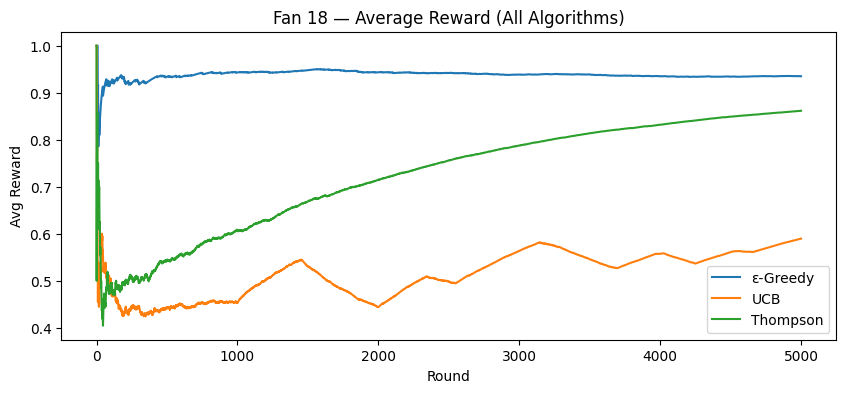

Running Fan 19...


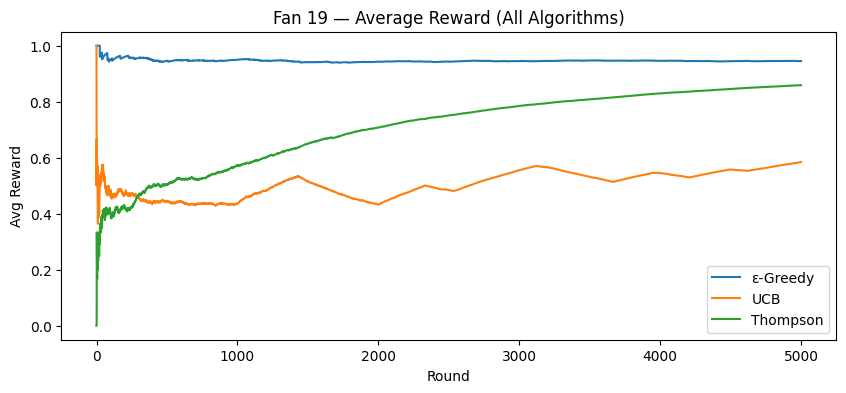

In [ ]:
T = 5000

all_arms_global = {
    "ε-Greedy": [],
    "UCB": [],
    "Thompson": []
}

for i in range(20):
    print(f"Running Fan {i}...")

    rewards, arms = run_all_algorithms_for_user(i, T)

    for algo in all_arms_global.keys():
      all_arms_global[algo].extend(arms[algo])

    # Plot per-fan avg reward
    plt.figure(figsize=(10,4))

    for name, r in rewards.items():
        avg_reward = np.cumsum(r) / np.arange(1, len(r)+1)
        plt.plot(avg_reward, label=name)

    plt.title(f"Fan {i} — Average Reward (All Algorithms)")
    plt.xlabel("Round")
    plt.ylabel("Avg Reward")
    plt.legend()
    plt.show()

# Cumulative Selection Frequency
This generates bar charts showing the Top 20 most-selected videos for each algorithm.

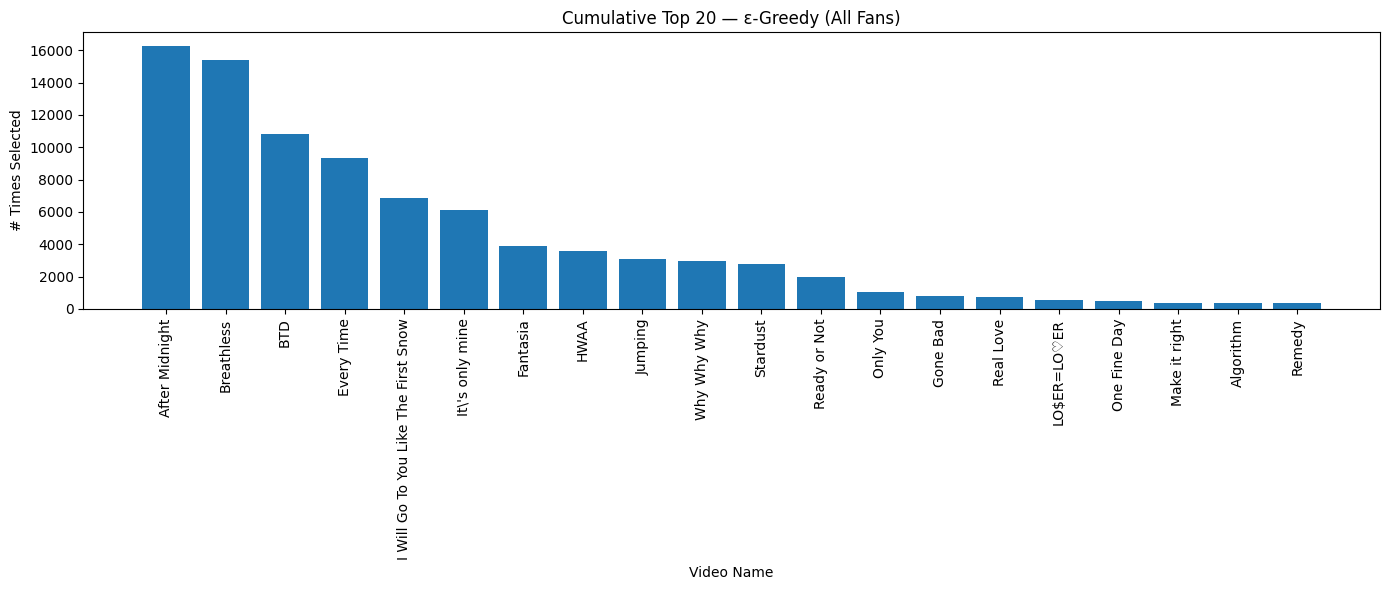

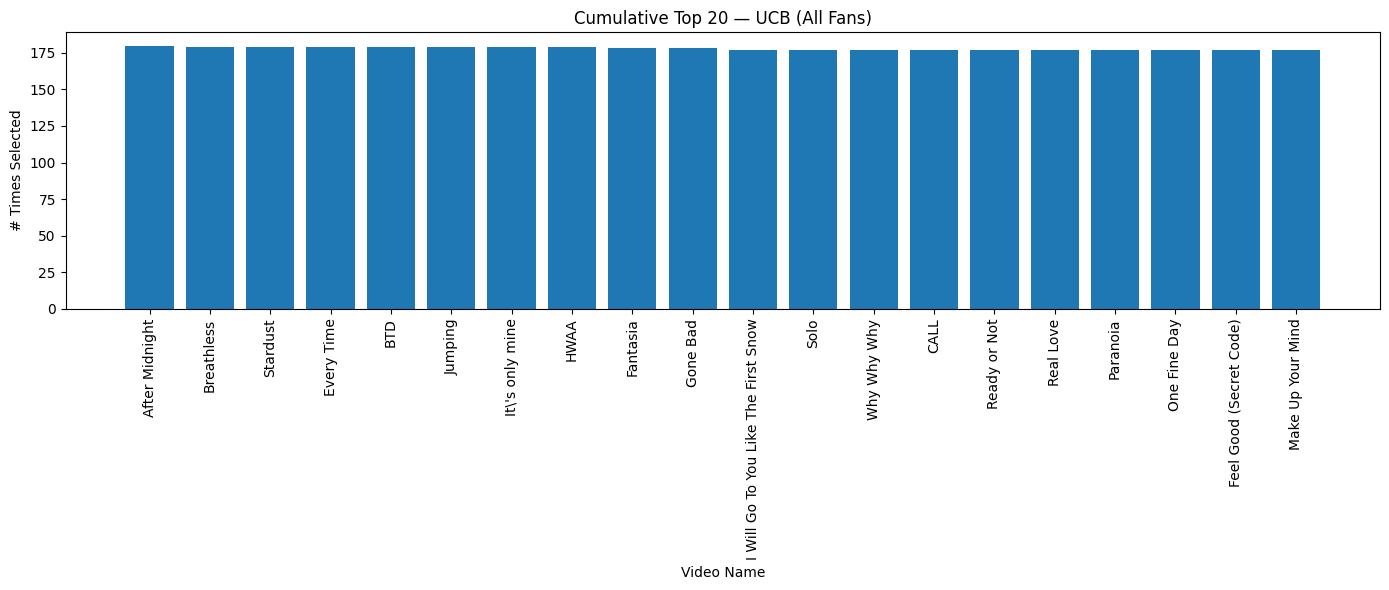

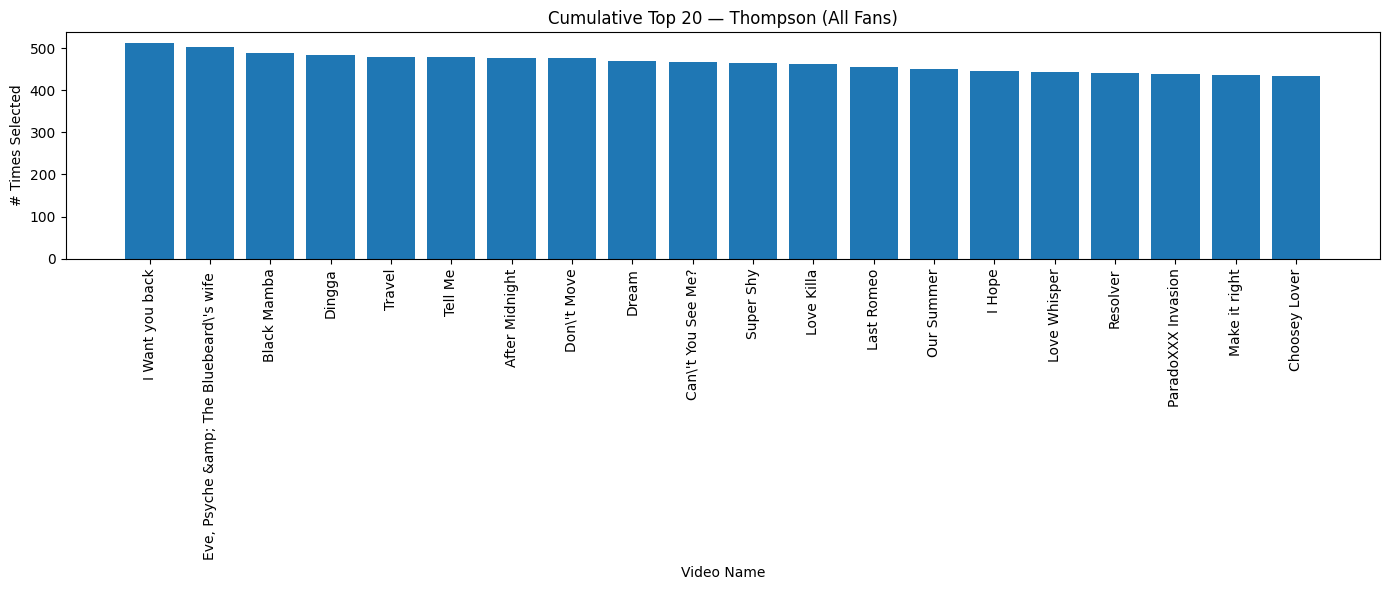

In [ ]:
# Selection Frequency Plot
def get_video_name(df, arm_idx):
    if "arm_id" not in df.columns:
        return f"Video {arm_idx}"

    row = df[df["arm_id"] == arm_idx]
    if row.empty:
        return f"Video {arm_idx}"

    row = row.iloc[0]

    for col in ["name_x", "name", "original_name"]:
        if col in df.columns and pd.notna(row[col]) and row[col] != "":
            return row[col]

    return f"Video {arm_idx}"


def plot_top_k_with_names(arms, merged_df, k=20, title="Top Videos"):
    unique, counts = np.unique(arms, return_counts=True)
    freq = dict(zip(unique, counts))

    top_items = sorted(freq.items(), key=lambda x: x[1], reverse=True)[:k]

    video_names = [get_video_name(merged_df, arm_idx) for arm_idx, _ in top_items]
    video_names = [name.replace("$", r"\$") for name in video_names]
    values = [count for _, count in top_items]

    plt.figure(figsize=(14,6))
    plt.bar(range(len(video_names)), values)
    plt.xticks(range(len(video_names)), video_names, rotation=90)
    plt.title(title)
    plt.ylabel("# Times Selected")
    plt.xlabel("Video Name")
    plt.tight_layout()
    plt.show()


plot_top_k_with_names(
    np.array(all_arms_global["ε-Greedy"]),
    merged,
    k=20,
    title="Cumulative Top 20 — ε-Greedy (All Fans)"
)

plot_top_k_with_names(
    np.array(all_arms_global["UCB"]),
    merged,
    k=20,
    title="Cumulative Top 20 — UCB (All Fans)"
)

plot_top_k_with_names(
    np.array(all_arms_global["Thompson"]),
    merged,
    k=20,
    title="Cumulative Top 20 — Thompson (All Fans)"
)


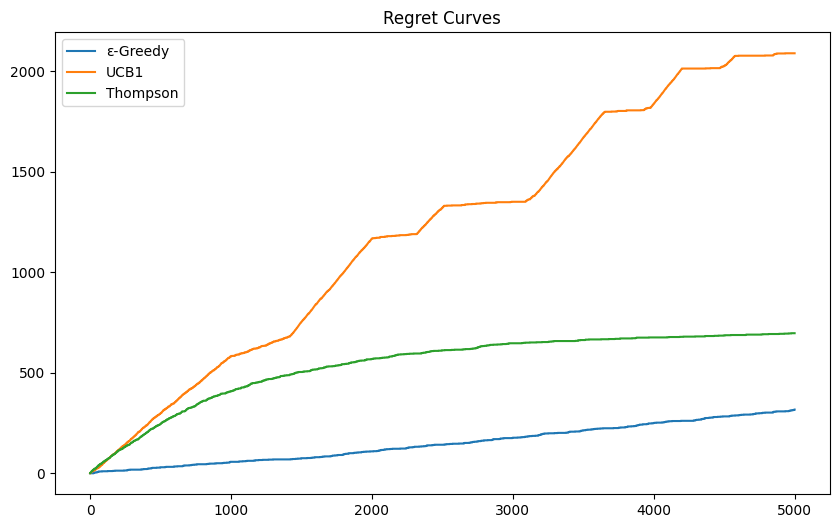

In [ ]:
# Regret Curve
# Estimate each video’s true avg reward across all fans
true_p = []
for i in range(n_arms):
    p_sum = 0
    for fan in fans:
        p_sum += fan(video_tensor[i].unsqueeze(0)).item()
    true_p.append(p_sum / num_fans)

best_p = max(true_p)

def regret_curve(rewards, best_p):
    expected = np.arange(1, len(rewards)+1) * best_p
    return expected - np.cumsum(rewards)

reward_eg,  arms_eg  = run_simulation(EpsilonGreedy(n_arms), T=5000, user_id=0)
reward_ucb, arms_ucb = run_simulation(UCB(n_arms), T=5000, user_id=0)
reward_ts,  arms_ts  = run_simulation(ThompsonSampling(n_arms), T=5000, user_id=0)

plt.figure(figsize=(10,6))
plt.plot(regret_curve(reward_eg,  best_p), label="ε-Greedy")
plt.plot(regret_curve(reward_ucb, best_p), label="UCB1")
plt.plot(regret_curve(reward_ts,  best_p), label="Thompson")
plt.title("Regret Curves")
plt.legend()
plt.show()

# Distribution of True Reward Probabilities
The goal of this is to understand how inherently "good" each video really is across the simulated fans.

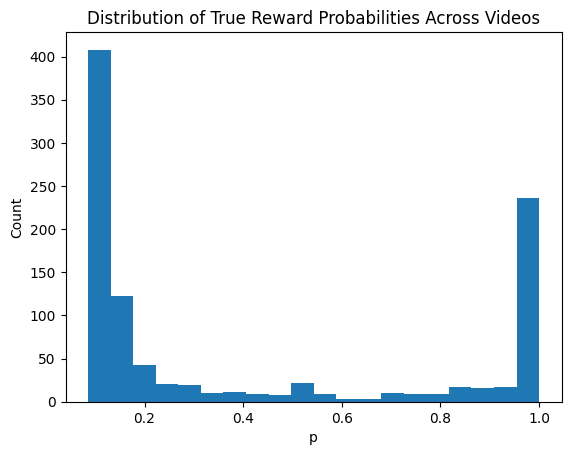

In [ ]:
plt.hist(true_p, bins=20)
plt.title("Distribution of True Reward Probabilities Across Videos")
plt.xlabel("p")
plt.ylabel("Count")
plt.show()

# KPOP MV Bandit Recommender System Flow Chart

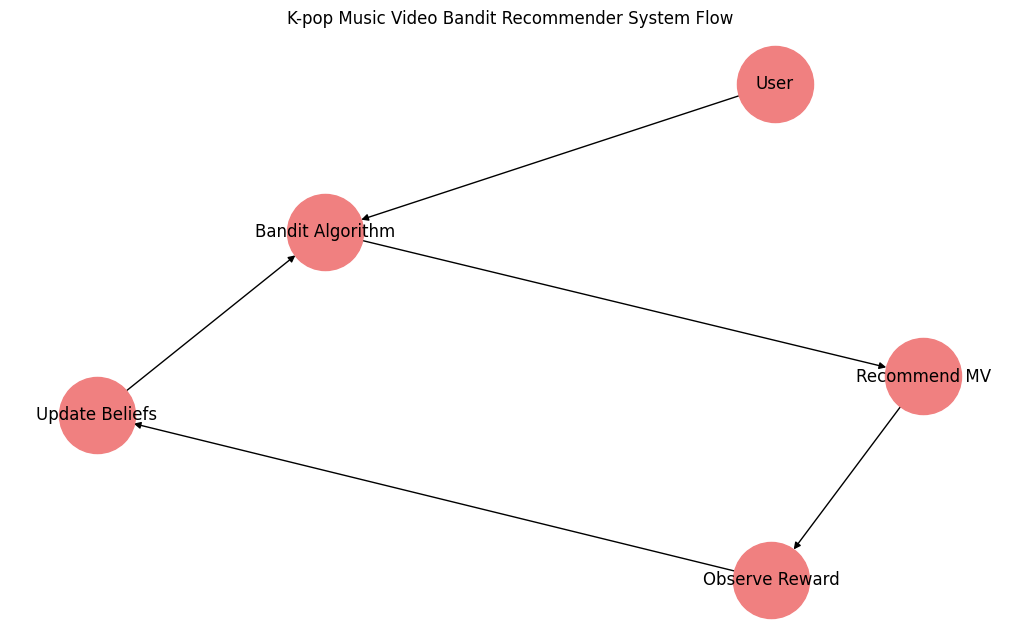

In [ ]:
import networkx as nx

G = nx.DiGraph()
G.add_edges_from([
    ("User", "Bandit Algorithm"),
    ("Bandit Algorithm", "Recommend MV"),
    ("Recommend MV", "Observe Reward"),
    ("Observe Reward", "Update Beliefs"),
    ("Update Beliefs", "Bandit Algorithm")
])

plt.figure(figsize=(10,6))
nx.draw(G, with_labels=True, node_size=3000, node_color="lightcoral", font_size=12)
plt.title("K-pop Music Video Bandit Recommender System Flow")
plt.show()
